<a href="https://colab.research.google.com/github/24ad043-alt/AI-Agents-Jobs-Ecosystem/blob/main/DL_ASS_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q tensorflow pandas openpyxl scikit-learn matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import csv
import tensorflow as tf
from google.colab import files
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import layers, Model

uploaded = files.upload()
file_path = next(iter(uploaded))

raw = pd.read_excel(file_path, header=None)

questions = []
answers = []

for value in raw.iloc[:, 0].dropna():
    row = next(csv.reader([str(value)]))
    if len(row) >= 2 and row[0].strip().lower() != "question":
        questions.append(row[0].strip().lower())
        answers.append(row[1].strip().lower())

df = pd.DataFrame({"question": questions, "answer": answers})
df = df.dropna().drop_duplicates(subset=["question"]).reset_index(drop=True)

questions = df["question"].tolist()
answers = ["starttoken " + a + " endtoken" for a in df["answer"]]

print("Total FAQ pairs:", len(questions))
print("Training data:", int(len(questions) * 0.8))
print("Validation data:", len(questions) - int(len(questions) * 0.8))

if len(questions) < 10:
    raise ValueError("Please provide at least 10 valid FAQ pairs.")

q_train, q_val, a_train, a_val = train_test_split(
    questions, answers, test_size=0.2, random_state=42
)

tokenizer = Tokenizer(oov_token="unk", filters="")
tokenizer.fit_on_texts(q_train + a_train)

vocab_size = len(tokenizer.word_index) + 1
q_len = max(len(q.split()) for q in questions)
a_len = max(len(a.split()) for a in answers)

def encode(texts, length):
    return pad_sequences(
        tokenizer.texts_to_sequences(texts),
        maxlen=length,
        padding="post"
    )

X_train = encode(q_train, q_len)
X_val = encode(q_val, q_len)
A_train = encode(a_train, a_len)
A_val = encode(a_val, a_len)

decoder_train = A_train[:, :-1]
target_train = A_train[:, 1:]
decoder_val = A_val[:, :-1]
target_val = A_val[:, 1:]

train_weights = (target_train != 0).astype("float32")
val_weights = (target_val != 0).astype("float32")

enc_input = layers.Input(shape=(q_len,))
enc_embed = layers.Embedding(
    vocab_size, 64, mask_zero=True
)(enc_input)

_, h, c = layers.LSTM(
    128, return_state=True
)(enc_embed)

dec_input = layers.Input(shape=(a_len - 1,))
dec_embed = layers.Embedding(
    vocab_size, 64, mask_zero=True
)(dec_input)

dec_output = layers.LSTM(
    128, return_sequences=True
)(dec_embed, initial_state=[h, c])

output = layers.Dense(
    vocab_size, activation="softmax"
)(dec_output)

model = Model([enc_input, dec_input], output)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    weighted_metrics=["sparse_categorical_accuracy"]
)

model.summary()

history = model.fit(
    [X_train, decoder_train],
    target_train[..., None],
    sample_weight=train_weights,
    validation_data=(
        [X_val, decoder_val],
        target_val[..., None],
        val_weights
    ),
    epochs=20,
    batch_size=8,
    verbose=1
)

results = model.evaluate(
    [X_val, decoder_val],
    target_val[..., None],
    sample_weight=val_weights,
    verbose=0
)

loss = results[0]
accuracy = results[1]
perplexity = np.exp(min(float(loss), 20))

print("\nValidation Loss:", round(float(loss), 4))
print("Validation Accuracy:", round(float(accuracy), 4))
print("Perplexity:", round(float(perplexity), 4))

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    history.history["sparse_categorical_accuracy"],
    label="Training Accuracy"
)
plt.plot(
    history.history["val_sparse_categorical_accuracy"],
    label="Validation Accuracy"
)
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

model.save("/content/college_chatbot.keras")
print("Model saved successfully.")

def get_answer(question):
    encoded_question = encode([question.lower().strip()], q_len)
    start_id = tokenizer.word_index.get("starttoken")

    if start_id is None:
        return "Unable to generate an answer."

    answer_tokens = [start_id]

    for _ in range(a_len - 1):
        decoder_input = pad_sequences(
            [answer_tokens],
            maxlen=a_len - 1,
            padding="post"
        )

        predictions = model.predict(
            [encoded_question, decoder_input],
            verbose=0
        )

        position = len(answer_tokens) - 1
        next_token = int(np.argmax(predictions[0, position]))
        word = tokenizer.index_word.get(next_token, "")

        if next_token == 0 or word == "endtoken":
            break

        answer_tokens.append(next_token)

    response = [
        tokenizer.index_word.get(token, "")
        for token in answer_tokens[1:]
    ]

    return " ".join(word for word in response if word)

print("\nSample Question:", questions[0])
print("Chatbot Answer:", get_answer(questions[0]))


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3408s 20us/step
Fold: 1
Fold: 2
Fold: 3
Fold: 4
Fold: 5

RESULTS AND COMPARISON
Without augmentation mean accuracy: 0.5252
Without augmentation standard deviation: 0.0162
With augmentation mean accuracy: 0.4781
With augmentation standard deviation: 0.016
Change in mean accuracy: -0.0471


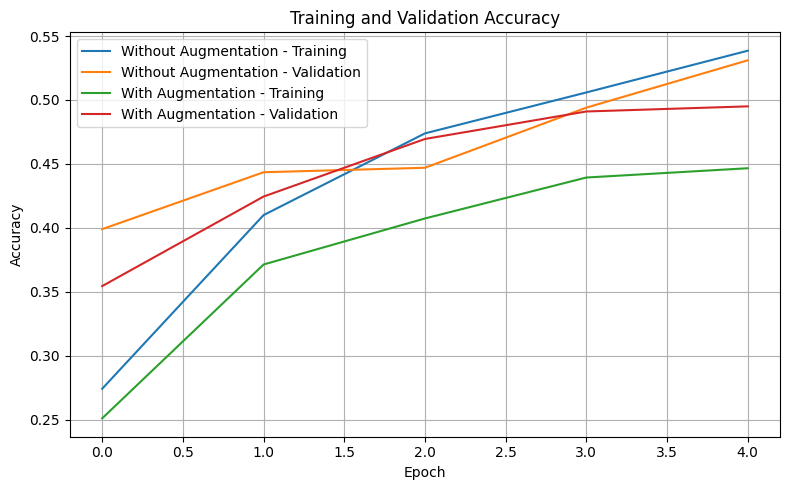

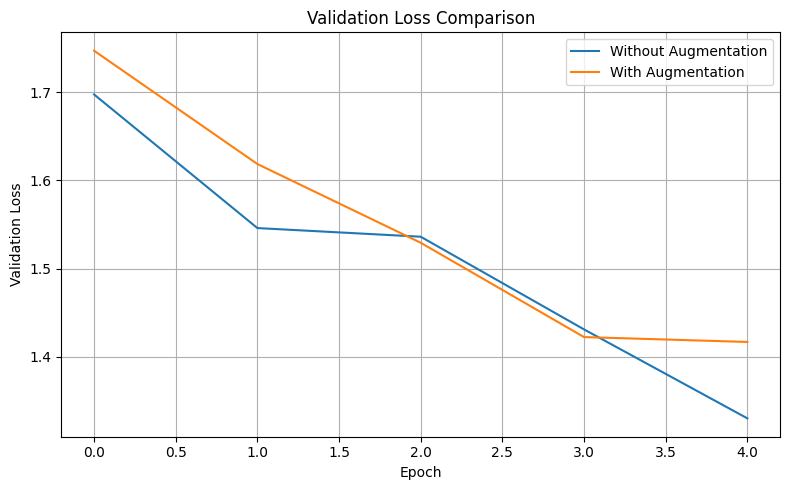


FOLD-WISE ACCURACY
Fold 1 | Without: 0.531 | With: 0.495
Fold 2 | Without: 0.4965 | With: 0.4525
Fold 3 | Without: 0.5225 | With: 0.4745
Fold 4 | Without: 0.546 | With: 0.4955
Fold 5 | Without: 0.53 | With: 0.473


In [ ]:
!pip install -q tensorflow scikit-learn matplotlib
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from sklearn.model_selection import KFold
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
x_train = x_train.astype("float32") / 255.0
y_train = y_train.flatten()
x_test = x_test.astype("float32") / 255.0
y_test = y_test.flatten()
x_data = x_train[:10000]
y_data = y_train[:10000]
def create_model(use_augmentation=False):
    model_layers = [layers.Input(shape=(32, 32, 3))]
    if use_augmentation:
        model_layers.extend([
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.1),
            layers.RandomZoom(0.1)])
    model_layers.extend([
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax")])
    model = models.Sequential(model_layers)
    model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
    return model
kf = KFold(n_splits=5, shuffle=True, random_state=42)
scores_without = []
scores_with = []
for fold, (train_idx, val_idx) in enumerate(kf.split(x_data), start=1):
    print("Fold:", fold)
    x_tr, x_val = x_data[train_idx], x_data[val_idx]
    y_tr, y_val = y_data[train_idx], y_data[val_idx]
    model_without = create_model(False)
    history_without = model_without.fit(x_tr, y_tr,validation_data=(x_val, y_val),epochs=5,batch_size=64,verbose=0)
    _, acc_without = model_without.evaluate(x_val, y_val, verbose=0)
    scores_without.append(acc_without)
    model_with = create_model(True)
    history_with = model_with.fit(x_tr, y_tr,validation_data=(x_val, y_val),epochs=5,batch_size=64,verbose=0)
    _, acc_with = model_with.evaluate(x_val, y_val, verbose=0)
    scores_with.append(acc_with)
    if fold == 1:
        first_history_without = history_without
        first_history_with = history_with
mean_without = np.mean(scores_without)
std_without = np.std(scores_without)
mean_with = np.mean(scores_with)
std_with = np.std(scores_with)
change = mean_with - mean_without
print("\nRESULTS AND COMPARISON")
print("Without augmentation mean accuracy:", round(mean_without, 4))
print("Without augmentation standard deviation:", round(std_without, 4))
print("With augmentation mean accuracy:", round(mean_with, 4))
print("With augmentation standard deviation:", round(std_with, 4))
print("Change in mean accuracy:", round(change, 4))

plt.figure(figsize=(8, 5))
plt.plot(first_history_without.history["accuracy"],label="Without Augmentation - Training")
plt.plot(first_history_without.history["val_accuracy"],label="Without Augmentation - Validation")
plt.plot(first_history_with.history["accuracy"],label="With Augmentation - Training")
plt.plot(first_history_with.history["val_accuracy"],label="With Augmentation - Validation")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(first_history_without.history["val_loss"],label="Without Augmentation")
plt.plot(first_history_with.history["val_loss"],label="With Augmentation")
plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nFOLD-WISE ACCURACY")
for i in range(5):
    print("Fold", i + 1,"| Without:", round(scores_without[i], 4),"| With:", round(scores_with[i], 4))
